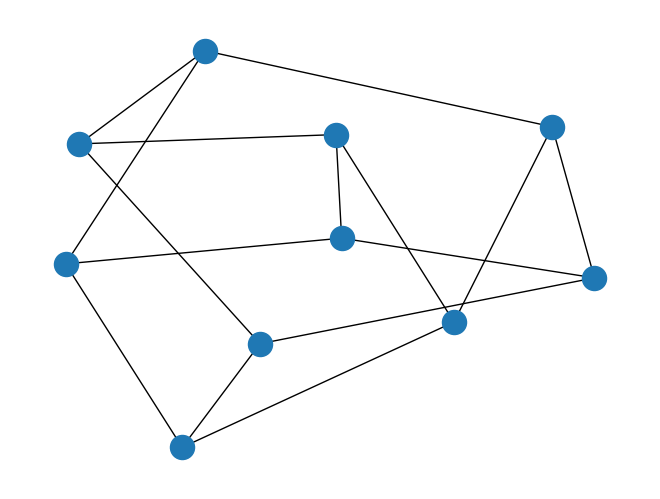

In [244]:
import networkx as nx
link = False

if link:
    G = nx.grid_2d_graph(2,2)
    mapping = {node: i for i, node in enumerate(G.nodes())}
    G = nx.relabel_nodes(G, mapping)
    nx.draw(G, with_labels=True)

if link:
# pathological 
    edges = [(0,1), (1,2), (2,1), (1,3),]
    G = nx.DiGraph()
    G.add_edges_from(edges)
    nx.draw(G, with_labels=True)

G = nx.petersen_graph()
nx.draw(G)


In [245]:
nx.incidence_matrix(G).toarray()

array([[1., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [1., 0., 0., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 1., 0., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 1., 0., 1., 1., 0., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0., 1., 0., 1., 0., 0., 0., 0., 0.],
       [0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 1., 1., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 1., 1., 0.],
       [0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 1., 0., 0., 0., 1.],
       [0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 1., 1., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 1., 1.]])

In [303]:
import pyomo.environ as pyo

K1, K2 = [0], [3]
N = len(G.nodes())
interdicted = [] # Assumed leader interdiction 


# Sets and Initialization 
model = pyo.ConcreteModel()
model.nodes = pyo.Set(initialize=list(G.nodes()))
model.edges = pyo.Set(initialize=[(u, v) for u, v in G.edges() for u, v in [(u, v), (v, u)]], dimen=2)
model.start_nodes = pyo.Set(initialize=K1)
model.end_nodes = pyo.Set(initialize=K2)
model.v = pyo.Param(model.nodes, initialize=lambda n: 0 if n in interdicted else 1, within=pyo.Binary, mutable=True)

# P1 decision variables
model.x = pyo.Var(model.edges, domain=pyo.Binary)      # Number of times directed edge is traversed
model.start = pyo.Var(model.nodes, domain=pyo.Binary)               # Which node is the start/end
model.end = pyo.Var(model.nodes, domain=pyo.Binary)
model.a = pyo.Var(model.edges, domain=pyo.NonNegativeReals)         # Auxiliary connectivity flow

# Objective and constraint lists
model.objective = pyo.Objective(expr=sum(model.x[e] for e in model.edges), sense=pyo.minimize)
model.visit_constraint = pyo.ConstraintList()
model.x_constraint = pyo.ConstraintList()
model.st_constraint = pyo.ConstraintList()
model.connectivity_constraint = pyo.ConstraintList()

# One s, t node selected
model.st_constraint.add(sum(model.start[n] for n in model.start_nodes) == 1)
model.st_constraint.add(sum(model.end[n] for n in model.nodes) == 1)

for n in model.nodes:
    # Surviving nodes must be visited
    model.visit_constraint.add(sum(model.x[e] for e in model.edges if n in e) >= model.v[n])
    model.visit_constraint.add(model.v[n] == 1)

    # Start/end cannot be interdicted
    model.st_constraint.add(model.start[n] <= model.v[n])
    model.st_constraint.add(model.end[n] <= model.v[n])
    # Nodes outside allowed start set cannot be starts
    if n not in model.start_nodes:
        model.st_constraint.add(model.start[n] == 0)
    if n not in model.end_nodes:
        model.st_constraint.add(model.end[n] == 0)

    # Walk flow balance
    inflow = sum(model.x[i, n] for i in model.nodes if (i, n) in model.edges)
    outflow = sum(model.x[n, j] for j in model.nodes if (n, j) in model.edges)
    model.x_constraint.add(outflow - inflow == model.start[n] - model.end[n])

    # Connectivity flow
    connect_in = sum(model.a[i, n] for i in model.nodes if (i, n) in model.edges)
    connect_out = sum(model.a[n, j] for j in model.nodes if (n, j) in model.edges)
    model.connectivity_constraint.add(connect_out - connect_in == N*model.start[n] - model.v[n])

# Interdicted nodes cannot be traversed
for i, j in model.edges:
    #model.connectivity_constraint.add(model.x[i, j] <= N*model.v[i])
    #model.connectivity_constraint.add(model.x[i, j] <= N*model.v[j])
    # Connectivity flow can only use traversed edges
    model.connectivity_constraint.add(model.a[i, j] <= N*model.x[i, j])

# Solve P1
model.solver = pyo.SolverFactory('appsi_highs')
result = model.solver.solve(model)

In [304]:
result

{'Problem': [{'Lower bound': 9.0, 'Upper bound': 9.0, 'Number of objectives': 1, 'Number of constraints': 0, 'Number of variables': 0, 'Sense': 'minimize'}], 'Solver': [{'Status': 'ok', 'Termination condition': 'optimal', 'Termination message': 'TerminationCondition.optimal'}]}

In [283]:
used_edges = []
for (u,v) in model.edges:
    if pyo.value(model.x[u,v])>0.1:
        used_edges.append((u,v))
used_edges

[(0, 5), (1, 2), (6, 1), (2, 7), (4, 3), (9, 4), (5, 8), (8, 6), (7, 9)]

In [284]:
MG = nx.MultiDiGraph()

start_node = next(n for n in model.nodes if pyo.value(model.start[n]) > 0.5)
for u, v in model.edges:
    count = int(round(pyo.value(model.x[u, v])))

    for _ in range(count):
        MG.add_edge(u, v)

walk = list(nx.eulerian_path(MG, source=start_node))
sequence = [start_node]

for u, v in walk:
    sequence.append(v)

print(f"start: {start_node}")
print("walk:", " -> ".join(map(str, sequence)))
print(f"end: {sequence[-1]}")

start: 0
walk: 0 -> 5 -> 8 -> 6 -> 1 -> 2 -> 7 -> 9 -> 4 -> 3
end: 3


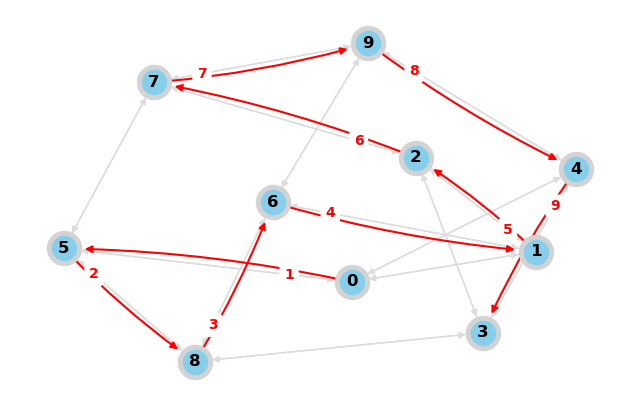

In [285]:
import matplotlib.pyplot as plt
import networkx as nx


# Base visualization options
kwargs = {'with_labels': True, 'font_weight': 'bold', 'node_color': 'lightgray', 'node_size': 600, 'edge_color': 'gainsboro', 'pos': nx.spring_layout(G),}
# 1. Convert sequence into sequential path edges: [(node1, node2), (node2, node3), ...]
path_edges = list(zip(sequence[:-1], sequence[1:]))
# 2. Draw the base graph (nodes + non-walk edges)
G = G.to_directed()

fig, axes = plt.subplots(figsize=(8, 5))
nx.draw_networkx(G, **kwargs)
# 3. Highlight nodes in the path
nx.draw_networkx_nodes(G, kwargs['pos'], nodelist=sequence, node_color='skyblue')
# 4. Highlight path edges with arrows to show travel sequence
edge_labels = {edge: f"{i+1}" for i, edge in enumerate(path_edges)}
nx.draw_networkx_edges(G, kwargs['pos'], edgelist=path_edges, edge_color='red', width=1.5, arrows=True, arrowsize=10, connectionstyle='arc3,rad=0.05', min_target_margin=15,)
nx.draw_networkx_edge_labels(G, kwargs['pos'], edge_labels=edge_labels, font_color='red', font_weight='bold', label_pos=0.2, rotate=False,)

#plt.title(r'Missing $a_{ij}$ Constriants', weight='bold')
plt.axis('off')
plt.savefig("C:/Users/Drew/Documents/MyFiles/work/networks/hamiltonian_paths/images/petersen_graph_walk.png")
plt.show()

In [288]:
2**10

1024

In [396]:
import itertools

class LL:
    def __init__(self, G, y_set=None, s_set=None, t_set=None):
        self.G = G
        self.K1 = s_set if s_set is not None else [list(G.nodes())[0]]
        self.K2 = t_set if t_set is not None else [list(G.nodes())[-1]]
        self.interdicted = y_set if y_set is not None else [] 
        self._initialize_model()

    def _initialize_model(self):
        self.model = pyo.ConcreteModel()
        model = self.model
        self.N = len(self.G.nodes())

        # Sets and Initialization 
        model.nodes = pyo.Set(initialize=list(self.G.nodes()))
        model.edges = pyo.Set(initialize=[(u, v) for u, v in self.G.edges() for u, v in [(u, v), (v, u)]], dimen=2)
        model.start_nodes = pyo.Set(initialize=self.K1)
        model.end_nodes = pyo.Set(initialize=self.K2)
        model.v = pyo.Param(model.nodes, initialize=lambda n: 0 if n in self.interdicted else 1, within=pyo.Binary, mutable=True)
        model.y = pyo.Param(model.nodes, initialize=[1-model.v[n] for n in model.nodes], within=pyo.Binary, mutable=True)

        # P1 decision variables
        model.x = pyo.Var(model.edges, domain=pyo.Binary)      # Number of times directed edge is traversed
        model.start = pyo.Var(model.nodes, domain=pyo.Binary)               # Which node is the start/end
        model.end = pyo.Var(model.nodes, domain=pyo.Binary)
        model.a = pyo.Var(model.edges, domain=pyo.NonNegativeReals)         # Auxiliary connectivity flow

        # Objective and constraint lists
        model.objective = pyo.Objective(expr=sum(model.x[e] for e in model.edges), sense=pyo.minimize)
        model.visit_constraint = pyo.ConstraintList()
        model.x_constraint = pyo.ConstraintList()
        model.st_constraint = pyo.ConstraintList()
        model.connectivity_constraint = pyo.ConstraintList()
        model.interdiction_constraint = pyo.ConstraintList()

        # One s, t node selected
        model.st_constraint.add(sum(model.start[n] for n in model.start_nodes) == 1)
        model.st_constraint.add(sum(model.end[n] for n in model.nodes) == 1)

        for n in model.nodes:
            # Surviving nodes must be visited
            model.visit_constraint.add(sum(model.x[e] for e in model.edges if n in e) >= model.v[n])

            # Start/end cannot be interdicted
            model.st_constraint.add(model.start[n] <= model.v[n])
            model.st_constraint.add(model.end[n] <= model.v[n])
            # Nodes outside allowed start set cannot be starts
            if n not in model.start_nodes:
                model.st_constraint.add(model.start[n] == 0)
            if n not in model.end_nodes:
                model.st_constraint.add(model.end[n] == 0)

            # Interdiction 
            model.interdiction_constraint.add(model.start[n] + model.y[n] <= 1)
            model.interdiction_constraint.add(model.end[n] + model.y[n] <= 1)

            # Walk flow balance
            inflow = sum(model.x[i, n] for i in model.nodes if (i, n) in model.edges)
            outflow = sum(model.x[n, j] for j in model.nodes if (n, j) in model.edges)
            model.x_constraint.add(outflow - inflow == model.start[n] - model.end[n])

            # Connectivity flow
            connect_in = sum(model.a[i, n] for i in model.nodes if (i, n) in model.edges)
            connect_out = sum(model.a[n, j] for j in model.nodes if (n, j) in model.edges)
            model.connectivity_constraint.add(connect_out - connect_in == sum(model.v[i] for i in model.nodes) * model.start[n] - model.v[n]
)

        # Interdicted nodes cannot be traversed
        for i, j in model.edges:
            # Connectivity flow can only use traversed edges
            model.connectivity_constraint.add(model.a[i, j] <= self.N*model.x[i, j])
            model.interdiction_constraint.add(model.x[i,j] <= 1-model.y[i]-model.y[j])

    def solve_model(self):
        self.model.solver = pyo.SolverFactory("appsi_highs")

        self.result = self.model.solver.solve(
            self.model,
            load_solutions=False
        )

        if self.result.solver.termination_condition == pyo.TerminationCondition.optimal:
            self.model.solutions.load_from(self.result)
            self.f_y = pyo.value(self.model.objective)
        else:
            self.f_y = 0
            

    def update_sets(self, y_set):
        model=self.model
        self.interdicted = set(y_set)
        for n in model.nodes:
            model.v[n] = 0 if n in self.interdicted else 1
            model.y[n] = 1 if n in self.interdicted else 0






In [392]:
ll = LL(G)
ll.solve_model()
ll.f_y

9.0

In [382]:
ll.update_sets({1})
ll.solve_model()
ll.f_y

8.0

In [383]:
ll = LL(G)

ll.solve_model()
print("y =", ll.interdicted)
print("f(y) =", ll.f_y)

y = []
f(y) = 9.0


In [384]:
ll.update_sets({3})

print("y =", ll.interdicted)

ll.solve_model()

print("f(y) =", ll.f_y)

y = {3}
f(y) = 9.000000000000002


In [397]:
import pandas as pd
results = []

nodes = list(G.nodes())

ll = LL(G)
for y_values in itertools.product([0, 1], repeat=len(nodes)):
    y_set = {n for n, y in zip(nodes, y_values) if y == 1}
    ll.update_sets(y_set)
    ll.solve_model()
    row = dict(zip(nodes, y_values))
    row["f_y"] = ll.f_y
    results.append(row)
df_results = pd.DataFrame(results)




In [400]:
df_results = df_results.sort_values("f_y", ascending=False)
df_best = df_results[df_results['f_y']==max(df_results['f_y'])]
df_best

,0,1,2,3,4,5,6,7,8,9,f_y
76,0,0,0,1,0,0,1,1,0,0,10.0
152,0,0,1,0,0,1,1,0,0,0,10.0
262,0,1,0,0,0,0,0,1,1,0,10.0
130,0,0,1,0,0,0,0,0,1,0,10.0
336,0,1,0,1,0,1,0,0,0,0,10.0


In [401]:
nodes = list(G.nodes())

marginal = []

for n in nodes:
    with_n = df_results[df_results[n] == 1]["f_y"]
    without_n = df_results[df_results[n] == 0]["f_y"]

    marginal.append({
        "node": n,
        "max_with": with_n.max(),
        "max_without": without_n.max(),
        "mean_with": with_n.mean(),
        "mean_without": without_n.mean(),
        "mean_delta": with_n.mean() - without_n.mean(),
    })

df_marginal = pd.DataFrame(marginal)

In [403]:
nodes = list(G.nodes())

marginal_results = []

for n in nodes:

    base = df_results[df_results[n] == 0].copy()

    for idx, row in base.iterrows():

        y_other = tuple(
            row[m] for m in nodes
        )

        mask = pd.Series(True, index=df_results.index)

        for m in nodes:
            if m == n:
                continue

            mask &= df_results[m] == row[m]

        comparison = df_results[
            mask & (df_results[n] == 1)
        ]

        if len(comparison) == 1:
            f_without = row["f_y"]
            f_with = comparison.iloc[0]["f_y"]

            marginal_results.append({
                "node": n,
                "f_without": f_without,
                "f_with": f_with,
                "delta": f_with - f_without
            })

df_marginal = pd.DataFrame(marginal_results)

In [405]:
df_effects = (df_marginal .groupby("node")["delta"] .agg(min_delta="min", mean_delta="mean", max_delta="max", std_delta="std") .reset_index())
df_effects

,node,min_delta,mean_delta,max_delta,std_delta
0,0,-10.0,-0.634766,0.0,2.255978
1,1,-10.0,-0.298828,2.0,1.605567
2,2,-10.0,-0.357422,2.0,1.751483
3,3,-10.0,-0.380859,2.0,1.810349
4,4,-10.0,-0.224609,1.0,1.412254
5,5,-10.0,-0.298828,2.0,1.605567
6,6,-10.0,-0.298828,2.0,1.605567
7,7,-10.0,-0.298828,2.0,1.605567
8,8,-10.0,-0.357422,2.0,1.751483
9,9,-10.0,-0.634766,0.0,2.255978


In [407]:
def surviving_graph(G, row):
    interdicted = {n for n in G.nodes() if row[n] == 1}
    return G.subgraph([n for n in G.nodes() if n not in interdicted]).copy()

features = []

for _, row in df_results.iterrows():

    G_survive = surviving_graph(G.to_undirected(), row)
    features.append({
        "num_interdicted": sum(row[n] for n in nodes), 
        "num_surviving": len(G_survive.nodes()), 
        "num_edges": len(G_survive.edges()), 
        "num_components": nx.number_connected_components(G_survive), 
        "f_y": row["f_y"]
    })

df_features = pd.DataFrame(features)

In [412]:
df_features["edge_bound"] = 2 * df_features["num_edges"]
df_features["edge_bound_gap"] = (df_features["edge_bound"] - df_features["f_y"])
df_features["node_bound"] = (2 * (df_features["num_surviving"] - 1))
df_features["node_bound_gap"] = (df_features["node_bound"] - df_features["f_y"])
df = df_features[df_features['f_y'] > 0]

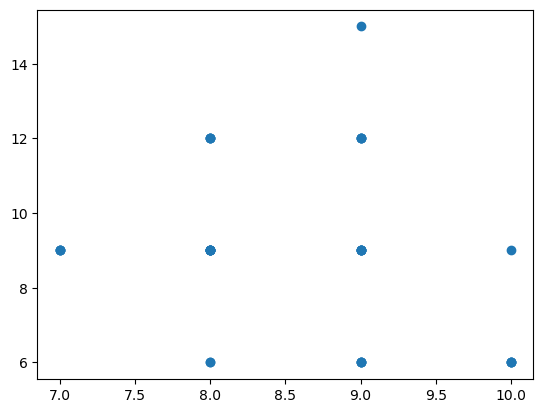

In [417]:
plt.scatter(df['f_y'], df['num_edges'])
plt.show()